In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv('ecommerce_data.csv')
data 

,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalAmount,Country,ProductCategory
0,C0045,2022-08-24 00:00:00,2,39.69,79.39,UK,Books
1,C0757,2022-07-01 00:00:00,1,414.09,414.09,Netherlands,Sports
2,C1643,2022-01-05 00:00:00,1,358.44,358.44,NaN,Sports
3,C0133,2023-07-01 00:00:00,1,150.21,150.21,UK,Clothing
4,C0941,2022-12-10 00:00:00,1,222.65,222.65,UK,Sports
...,...,...,...,...,...,...,...
8200,C0089,2022-11-01 00:00:00,2,43.18,86.36,UK,Beauty
8201,C0737,2023-03-06 00:00:00,1,5.02,5.02,Spain,Books
8202,C0128,2022-09-19 00:00:00,1,15.60,15.60,UK,Beauty
8203,C0388,2022-03-25 00:00:00,1,0.00,249.18,UK,Home & Garden


In [5]:
data.columns

Index(['CustomerID', 'InvoiceDate', 'Quantity', 'UnitPrice', 'TotalAmount',
       'Country', 'ProductCategory'],
      dtype='str')

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8205 entries, 0 to 8204
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       8189 non-null   str    
 1   InvoiceDate      8205 non-null   str    
 2   Quantity         8205 non-null   int64  
 3   UnitPrice        8205 non-null   float64
 4   TotalAmount      8205 non-null   float64
 5   Country          6866 non-null   str    
 6   ProductCategory  8205 non-null   str    
dtypes: float64(2), int64(1), str(4)
memory usage: 740.4 KB


<Axes: ylabel='Frequency'>

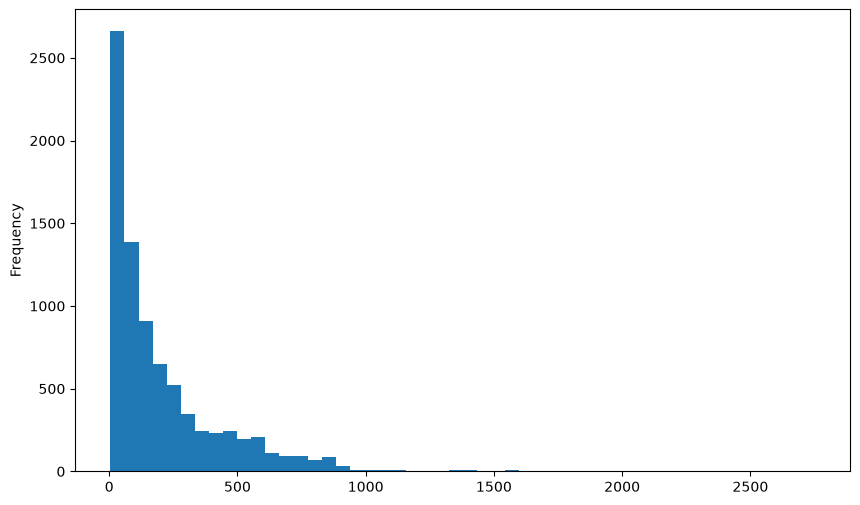

In [7]:
data["TotalAmount"].plot(kind='hist', bins=50, figsize=(10, 6))

<Axes: xlabel='Country'>

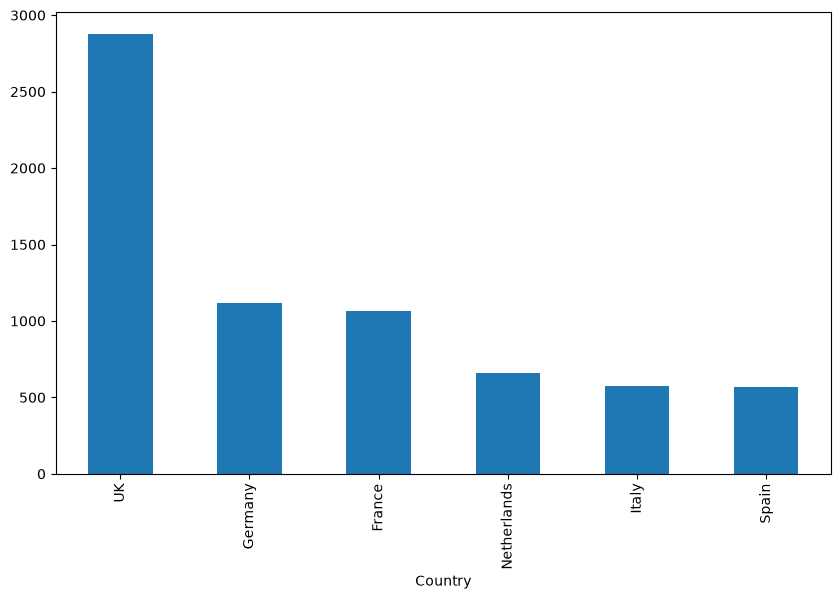

In [9]:
data["Country"].value_counts().plot(kind='bar', figsize=(10, 6))

In [10]:
data["Country"].value_counts()

Country
UK             2878
Germany        1116
France         1067
Netherlands     661
Italy           575
Spain           569
Name: count, dtype: int64

In [15]:
data[["TotalAmount", "UnitPrice"]].sort_values(by="UnitPrice", ascending=True)

,TotalAmount,UnitPrice
6094,33.34,0.00
5103,10.41,0.00
1221,29.52,0.00
3970,36.28,0.00
7185,92.69,0.00
...,...,...
1084,894.96,894.96
2316,896.26,896.26
1821,896.94,896.94
5467,897.67,897.67


In [20]:
data[data["UnitPrice"] <= 0].shape

(24, 7)

In [21]:
def calculate_unit_price(df):
    df = df.copy()
    df["CalculatedUnitPrice"] = df["TotalAmount"] / df["Quantity"]
    return df

In [ ]:
calculated_data = calculate_unit_price(data)


In [26]:
calculated_data[["CalculatedUnitPrice", "UnitPrice"]][calculated_data["UnitPrice"] <= 0]

,CalculatedUnitPrice,UnitPrice
184,672.460,0.0
772,17.090,0.0
840,371.920,0.0
964,269.020,0.0
1221,29.520,0.0
2615,463.600,0.0
3577,24.040,0.0
3639,54.190,0.0
3970,36.280,0.0
4273,105.270,0.0


In [28]:
calculated_data[["CalculatedUnitPrice", "UnitPrice"]].sort_values(by="UnitPrice", ascending=True)

,CalculatedUnitPrice,UnitPrice
6094,33.34,0.00
5103,10.41,0.00
1221,29.52,0.00
3970,36.28,0.00
7185,92.69,0.00
...,...,...
1084,894.96,894.96
2316,896.26,896.26
1821,896.94,896.94
5467,897.67,897.67


In [ ]:
calculated_data[["CalculatedUnitPrice", "UnitPrice"]]

,CalculatedUnitPrice,UnitPrice
0,39.695,39.69
1,414.090,414.09
2,358.440,358.44
3,150.210,150.21
4,222.650,222.65
...,...,...
8200,43.180,43.18
8201,5.020,5.02
8202,15.600,15.60
8203,249.180,0.00


In [65]:
mismatch = ~np.isclose(
    calculated_data["CalculatedUnitPrice"],
    calculated_data["UnitPrice"],
    rtol=0,
    atol=0.001
)

calculated_data[mismatch][["CalculatedUnitPrice", "UnitPrice"]]

,CalculatedUnitPrice,UnitPrice
0,39.695,39.69
7,127.410,150.28
15,38.722,38.72
20,508.235,508.24
26,7.270,8.66
...,...,...
8183,483.090,597.83
8189,208.300,281.20
8197,96.660,127.47
8203,249.180,0.00
